# Bài 17 · Khôi phục dấu tiếng Việt: mô hình kênh nhiễu và Viterbi

**Thời lượng gợi ý:** 180 phút · **Cần:** Bài 1, Bài 4 (và Bài 12 cho mục 7) · **Không cần GPU** (mục 8 là tùy chọn, dùng GPU)

> **Bài mở rộng.** Không bắt buộc cho lộ trình chính, nhưng nối nhiều ý của khóa học vào một bài toán *thuần tiếng Việt*: n-gram (Bài 4), giải mã Viterbi (Bài 11), va chạm khi bỏ dấu (Bài 1), tìm kiếm với truy vấn không dấu (Bài 12).

## Mục tiêu

1. Mô tả bài toán **khôi phục dấu** và đo mức **mơ hồ** của nó trên dữ liệu thật.
2. Phát biểu bài toán bằng **mô hình kênh nhiễu**: $\hat y=\arg\max_y P(y)\,P(x\mid y)$.
3. Cài đặt từ con số 0: từ điển ứng viên, mô hình ngôn ngữ n-gram nội suy, **giải mã Viterbi** trên lưới ứng viên.
4. Đánh giá đúng cách: độ chính xác theo token, theo câu, theo token *mơ hồ*; **trong miền và ngoài miền**.
5. Dùng khôi phục dấu để cứu bài toán tìm kiếm với truy vấn không dấu, và so với cách đơn giản hơn (bỏ dấu cả hai phía).
6. So sánh mô hình nhỏ chuyên biệt với một LLM nhỏ dùng prompt (tùy chọn).

In [1]:
import sys, pathlib

ROOT = pathlib.Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import time, difflib
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from nlpvi import DATA_DIR, load_faq, load_splits, set_seed, split_sentences, strip_accents
from nlpvi.diacritics import DiacriticRestorer, tach_token

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
set_seed(42)

## 1. Bài toán và vì sao nó khó

Người dùng điện thoại, bàn phím không có bộ gõ tiếng Việt, hoặc dữ liệu cũ đều có thể cho ra **văn bản không dấu**: "toi muon doi tra hang". Ta muốn khôi phục "tôi muốn đổi trả hàng".

Khó vì phép bỏ dấu **không khả nghịch**: nhiều âm tiết khác nhau cùng thành một dạng không dấu (Bài 1 đã đo "va chạm" này). Dạng "ma" có thể là *ma, mà, má, mã, mả, mạ*; "ban" có thể là *ban, bàn, bán, bạn, bản, bấn*... Chọn dạng nào phụ thuộc **ngữ cảnh**: "mua ban" → *mua bán*, nhưng "ban be" → *bạn bè*.

Ta cần dữ liệu thật để đo. Dùng ba kho văn bản có dấu, mỗi kho một "miền":

| Kho | Miền | Ghi chú |
|---|---|---|
| UIT-VSFC | phản hồi của sinh viên về giảng viên, chương trình học | ngắn, thân mật, ≈ 11 nghìn câu train |
| PhoNER (bản đã tách từ) | tin tức COVID-19 | ≈ 5 nghìn câu train, văn phong báo chí |
| Đánh giá tổng hợp của khóa học | mua sắm trực tuyến | viết từ khuôn mẫu, chỉ để so sánh |

Mọi văn bản được đưa về **chữ thường**, Unicode NFC, tách thành *âm tiết + dấu câu* (khớp cách UIT-VSFC đã tách). Phần chữ hoa chỉ là việc phục hồi hình thức, ta bỏ qua trong thí nghiệm.

In [2]:
def tai_kho_van_ban():
    """Trả về {tên kho: (câu train, câu valid)}, mỗi câu là list âm tiết CÓ DẤU, chữ thường."""
    kho = {}
    rev_tr, rev_va, _ = load_splits()
    kho["tổng hợp (mua sắm)"] = ([tach_token(t) for t in rev_tr["text"]], [tach_token(t) for t in rev_va["text"]])
    try:
        from datasets import load_dataset
        uit = load_dataset("uitnlp/vietnamese_students_feedback", revision="refs/convert/parquet")
        kho["UIT-VSFC (sinh viên)"] = ([tach_token(s) for s in uit["train"]["sentence"]],
                                       [tach_token(s) for s in uit["validation"]["sentence"]])
        pho = load_dataset("truongpdd/NER-covid-vietnamese-word")
        tach = lambda rows: [tach_token(" ".join(t).replace("_", " ")) for t in rows["tokens"]]
        kho["PhoNER (tin tức COVID)"] = (tach(pho["train"]), tach(pho["validation"]))
    except Exception as e:
        print(f"⚠ Không tải được dữ liệu thật ({type(e).__name__}). Chỉ dùng kho tổng hợp: kết quả sẽ CAO GIẢ TẠO vì dữ liệu viết từ khuôn mẫu.")
    return kho

KHO = tai_kho_van_ban()
bang = pd.DataFrame({ten: {"câu train": len(tr), "token train": sum(map(len, tr)), "câu valid": len(va)} for ten, (tr, va) in KHO.items()}).T
display(bang)
uit_ten = "UIT-VSFC (sinh viên)" if "UIT-VSFC (sinh viên)" in KHO else "tổng hợp (mua sắm)"
cau_train, cau_valid = KHO[uit_ten]
print("Ví dụ:", " ".join(cau_train[3]))

,câu train,token train,câu valid
tổng hợp (mua sắm),1262,17296,269
UIT-VSFC (sinh viên),11426,163559,1583
PhoNER (tin tức COVID),5027,171540,2000


Ví dụ: chưa áp dụng công nghệ thông tin và các thiết bị hỗ trợ cho việc giảng dạy .


### 1.1 Đo mức mơ hồ

Với mỗi dạng không dấu $b$, gọi $C(b)$ là tập các dạng có dấu đã gặp trong dữ liệu train. Ta đếm: bao nhiêu phần trăm *token* có $|C(b)|>1$ (tức là không thể quyết định chỉ từ chữ), và những dạng không dấu mơ hồ nhất.

In [3]:
ung_vien = defaultdict(Counter)                    # dạng không dấu -> Counter(các dạng có dấu)
for s in cau_train:
    for w in s:
        ung_vien[strip_accents(w)][w] += 1

chu = [w for s in cau_train for w in s if w.isalpha()]
mo_ho = np.mean([len(ung_vien[strip_accents(w)]) > 1 for w in chu])
khong_doi = np.mean([strip_accents(w) == w for w in chu])
print(f"{len(ung_vien):,} dạng không dấu khác nhau trong {len(chu):,} token chữ")
print(f"Token có >1 dạng có dấu khả dĩ (mơ hồ): {mo_ho:.1%} | token vốn không có dấu (bỏ dấu không đổi gì): {khong_doi:.1%}")

top = sorted(ung_vien.items(), key=lambda kv: -len(kv[1]))[:8]
display(pd.DataFrame([{"dạng không dấu": b, "số dạng có dấu": len(c), "các dạng (tần suất)": ", ".join(f"{w} ({n})" for w, n in c.most_common(6))} for b, c in top]).set_index("dạng không dấu"))

1,445 dạng không dấu khác nhau trong 144,072 token chữ
Token có >1 dạng có dấu khả dĩ (mơ hồ): 86.0% | token vốn không có dấu (bỏ dấu không đổi gì): 12.3%


,số dạng có dấu,các dạng (tần suất)
dạng không dấu,,
doi,13,"đổi (136), đối (113), đôi (107), dõi (23), đời..."
de,12,"dễ (1438), để (823), đề (494), đẻ (2), dể (2),..."
do,12,"đồ (253), đó (197), đỡ (143), độ (120), do (11..."
day,11,"dạy (3156), đầy (259), đây (43), dãy (8), dậy ..."
dung,11,"dụng (416), dung (395), đúng (287), dùng (56),..."
dan,11,"dẫn (456), dặn (14), đàn (9), dần (6), đặn (6)..."
co,10,"có (2031), cô (1202), cơ (143), cố (61), cổ (3..."
dang,10,"dạng (68), đang (61), dàng (36), đăng (25), đá..."


**Đọc kết quả (1.1).** Trong 144 nghìn token chữ chỉ có 1.445 dạng không dấu khác nhau, nhưng **86% số token** thuộc dạng có hơn một cách viết có dấu khả dĩ; chỉ 12,3% token vốn không có dấu. Các dạng mơ hồ nhất không phải từ hiếm: "doi" có 13 dạng (*đổi* 136 lần, *đối* 113, *đôi* 107...), "de" có 12 dạng (*dễ* 1.438, *để* 823, *đề* 494...). Phép bỏ dấu "nén" nhiều âm tiết thành một, nên **không có quy tắc chữ-thành-chữ nào giải được**; muốn chọn đúng phải nhìn ngữ cảnh.

## 2. Mô hình kênh nhiễu

Coi văn bản có dấu $y$ là tín hiệu gốc, còn văn bản không dấu $x$ là thứ đi qua một "kênh nhiễu" làm rơi dấu. Theo Bayes:

$$\hat y=\arg\max_y P(y\mid x)=\arg\max_y P(y)\,P(x\mid y)$$

Ở đây phép bỏ dấu là **tất định**: $P(x\mid y)=1$ nếu bỏ dấu của $y$ đúng bằng $x$, ngược lại bằng 0. Nghĩa là *chỉ còn* hai việc: (1) liệt kê các $y$ khả dĩ, tức với mỗi âm tiết không dấu $x_i$ lấy tập ứng viên $C(x_i)$; (2) chọn chuỗi có **xác suất ngôn ngữ $P(y)$ lớn nhất** — chính là mô hình ngôn ngữ n-gram của Bài 4.

Số chuỗi ứng viên tăng theo cấp số nhân (tích các $|C(x_i)|$) nên không thể liệt kê hết; dùng **quy hoạch động Viterbi** trên một *lưới* (lattice): mỗi cột là một âm tiết, mỗi ô là một ứng viên. Với bigram, trạng thái là ứng viên của cột hiện tại; với trigram, trạng thái là *cặp* ứng viên của hai cột liền nhau.

## 3. Baseline: luôn chọn dạng phổ biến nhất

Baseline mạnh và rẻ nhất: với mỗi âm tiết không dấu, chọn dạng có dấu **xuất hiện nhiều nhất** trong train (không nhìn ngữ cảnh). Cùng với baseline "không làm gì" (giữ nguyên văn bản không dấu), ta có hai mốc để biết mô hình có ích thật không.

In [4]:
def danh_gia(du_doan, cau, n=None):
    """du_doan: hàm nhận list dạng không dấu, trả list dạng có dấu. Trả về độ chính xác token / token mơ hồ / câu."""
    ok = tot = amb_ok = amb_tot = sent_ok = 0
    cau = cau[:n] if n else cau
    for s in cau:
        pred = du_doan([strip_accents(w) for w in s])
        dung = [a == b for a, b in zip(pred, s)]
        ok += sum(dung); tot += len(s); sent_ok += all(dung)
        for w, d in zip(s, dung):
            if len(ung_vien.get(strip_accents(w), ())) > 1:
                amb_tot += 1; amb_ok += d
    return {"token": round(ok / tot, 4), "token mơ hồ": round(amb_ok / max(amb_tot, 1), 4), "câu đúng hoàn toàn": round(sent_ok / len(cau), 3)}

def pho_bien_nhat(bases):
    return [ung_vien[b].most_common(1)[0][0] if b in ung_vien else b for b in bases]

ket_qua = {"không làm gì": danh_gia(lambda b: b, cau_valid),
           "dạng phổ biến nhất (unigram)": danh_gia(pho_bien_nhat, cau_valid)}
display(pd.DataFrame(ket_qua).T)

,token,token mơ hồ,câu đúng hoàn toàn
không làm gì,0.2309,0.0989,0.003
dạng phổ biến nhất (unigram),0.8703,0.8303,0.287


**Đọc kết quả (3).** "Không làm gì" chỉ đúng 23,1% token (gồm dấu câu và 12% token vốn không có dấu). Chọn dạng phổ biến nhất đã đưa token lên **87,0%** (83,0% trên token mơ hồ): một mốc rất mạnh, mọi mô hình phức tạp hơn phải *vượt* nó. Nhưng chỉ **28,7% câu** đúng hoàn toàn: câu trung bình dài ≈ 14 token, sai một token là cả câu sai.

## 4. Mô hình ngôn ngữ và giải mã Viterbi

### 4.1 Mô hình ngôn ngữ trigram nội suy

Giống Bài 4, nhưng trên **âm tiết** thay vì từ. Xác suất nội suy

$$P(w\mid u,v)=\lambda_3\frac{c(u,v,w)}{c(u,v)}+\lambda_2\frac{c(v,w)}{c(v)}+\lambda_1\frac{c(w)+k}{N+kV},\qquad(\lambda_1,\lambda_2,\lambda_3)=(0{,}1;\,0{,}4;\,0{,}5)$$

Khi một ngữ cảnh chưa từng xuất hiện (mẫu số bằng 0), ta bỏ bậc tương ứng và **chuẩn hóa lại** các trọng số còn lại. Không điều chỉnh $\lambda$ trên tập đánh giá (xem bài tập 1).

In [5]:
class LM:
    """Trigram nội suy trên âm tiết, có đệm <s> <s> ... </s>."""
    def __init__(self, cau, lam=(0.1, 0.4, 0.5), k=0.01):
        self.lam, self.k = lam, k
        self.uni, self.bi, self.tri = Counter(), Counter(), Counter()
        self.bi_ctx, self.tri_ctx = Counter(), Counter()
        for s in cau:
            p = ["<s>", "<s>"] + list(s) + ["</s>"]
            for i in range(2, len(p)):
                self.uni[p[i]] += 1; self.bi[(p[i - 1], p[i])] += 1; self.tri[(p[i - 2], p[i - 1], p[i])] += 1
                self.bi_ctx[p[i - 1]] += 1; self.tri_ctx[(p[i - 2], p[i - 1])] += 1
        self.N, self.V = sum(self.uni.values()), len(self.uni) + 1

    def logp(self, u, v, w):
        l1, l2, l3 = self.lam
        p1 = (self.uni[w] + self.k) / (self.N + self.k * self.V)
        t, b = self.tri_ctx[(u, v)], self.bi_ctx[v]
        w3, w2 = (l3 if t else 0.0), (l2 if b else 0.0)
        p = l1 * p1 + (w2 * self.bi[(v, w)] / b if w2 else 0.0) + (w3 * self.tri[(u, v, w)] / t if w3 else 0.0)
        return np.log(p / (l1 + w2 + w3))

lm = LM(cau_train)

def log_p_chuoi(lm, toks):
    p = ["<s>", "<s>"] + list(toks) + ["</s>"]
    return sum(lm.logp(p[i - 2], p[i - 1], p[i]) for i in range(2, len(p)))

for chuoi in ["tôi muốn đổi trả hàng", "tôi muốn đỗi tra hang", "tôi muốn đổi trả hàng ."]:
    print(f"log P({chuoi!r}) = {log_p_chuoi(lm, chuoi.split()):.2f}")

log P('tôi muốn đổi trả hàng') = -45.75
log P('tôi muốn đỗi tra hang') = -59.03
log P('tôi muốn đổi trả hàng .') = -44.04


### 4.2 Viterbi trên lưới ứng viên

Với trigram, trạng thái tại cột $i$ là cặp $(y_{i-1},y_i)$. Giữ cho mỗi trạng thái *điểm tốt nhất* và *con trỏ lùi*; cuối cùng lần ngược để lấy chuỗi tốt nhất. Độ phức tạp $O(T\cdot m^3)$ với $m$ là số ứng viên tối đa mỗi cột — nhỏ vì $m$ chỉ cỡ vài chục.

In [6]:
def giai_ma(lm, bases, ung_vien_cua):
    C = [ung_vien_cua(b) for b in bases]
    truoc = {("<s>", "<s>"): 0.0}
    lui = []
    for ci in C:
        hien, con_tro = {}, {}
        for (u, v), diem in truoc.items():
            for w in ci:
                d = diem + lm.logp(u, v, w)
                if (v, w) not in hien or d > hien[(v, w)]:
                    hien[(v, w)], con_tro[(v, w)] = d, (u, v)
        lui.append(con_tro); truoc = hien
    # kết thúc bằng </s>
    cuoi = max(truoc, key=lambda s: truoc[s] + lm.logp(s[0], s[1], "</s>"))
    out, khoa = [], cuoi
    for i in range(len(C) - 1, -1, -1):
        out.append(khoa[1]); khoa = lui[i][khoa]
    return out[::-1]

ung_vien_cua = lambda b: [w for w, _ in ung_vien[b].most_common()] if b in ung_vien else [b]
mau = ["toi", "muon", "doi", "tra", "hang"]
print("ứng viên:", [ung_vien_cua(b)[:4] for b in mau])
print("Viterbi :", giai_ma(lm, mau, ung_vien_cua))

ứng viên: [['tới', 'tôi', 'tối', 'tòi'], ['muốn', 'muộn', 'mượn', 'muôn'], ['đổi', 'đối', 'đôi', 'dõi'], ['tra', 'trả'], ['hàng', 'hăng', 'hằng', 'hạng']]
Viterbi : ['tôi', 'muốn', 'đổi', 'tra', 'hàng']


In [7]:
t0 = time.time()
ket_qua["trigram + Viterbi (tự cài)"] = danh_gia(lambda b: giai_ma(lm, b, ung_vien_cua), cau_valid)
print(f"đánh giá {len(cau_valid)} câu trong {time.time() - t0:.0f}s")
display(pd.DataFrame(ket_qua).T)

đánh giá 1583 câu trong 2s


,token,token mơ hồ,câu đúng hoàn toàn
không làm gì,0.2309,0.0989,0.003
dạng phổ biến nhất (unigram),0.8703,0.8303,0.287
trigram + Viterbi (tự cài),0.9778,0.9722,0.798


**Đọc kết quả (4).** Thêm ngữ cảnh (trigram + Viterbi) đưa token lên **97,8%**, token mơ hồ lên 97,2% và câu đúng hoàn toàn lên **79,8%** (từ 28,7%). Tỉ lệ sai theo token giảm từ 13,0% xuống 2,2%: bớt khoảng 5/6 số lỗi chỉ bằng cách nhìn hai âm tiết đứng trước. Mô hình thật sự dùng ngữ cảnh: log P của "tôi muốn đổi trả hàng" (−45,75) cao hơn hẳn bản sai dấu "tôi muốn đỗi tra hang" (−59,03). Nhớ rằng đây là kết quả **trong miền** (huấn luyện và đánh giá cùng là phản hồi của sinh viên); mục 5 cho thấy nó tách xa thực tế thế nào.

### 4.3 Bản đóng gói trong `nlpvi` và kiểm tra tương đương

Gói `nlpvi.diacritics` giữ bản hoàn chỉnh của đoạn mã trên (thêm: xử lý chuỗi bất kỳ, giữ nguyên khoảng trắng/dấu câu/kiểu viết hoa). Ta kiểm tra bản đóng gói cho **đúng cùng kết quả** với bản tự cài ở trên:

In [8]:
mo_hinh = DiacriticRestorer(bac=3).fit(cau_train)
mau_kt = cau_valid[:300]
giong = all(mo_hinh.restore_tokens([strip_accents(w) for w in s]) == giai_ma(lm, [strip_accents(w) for w in s], ung_vien_cua) for s in mau_kt)
print("Bản đóng gói giống hệt bản tự cài trên 300 câu:", giong)
for cau in ["Toi muon doi tra hang vi san pham bi loi.", "Giang vien day rat de hieu, nhung phong hoc hoi nong!", "MUA BAN ONLINE"]:
    print(f"{cau!r:62s} → {mo_hinh.restore(cau)!r}")

Bản đóng gói giống hệt bản tự cài trên 300 câu: True
'Toi muon doi tra hang vi san pham bi loi.'                    → 'Tôi muốn đổi tra hàng vì sản phẩm bị lỗi.'
'Giang vien day rat de hieu, nhung phong hoc hoi nong!'        → 'Giảng viên dạy rất dễ hiểu, nhưng phòng học hơi nóng!'
'MUA BAN ONLINE'                                               → 'MUA BẠN ONLINE'


**Đọc kết quả (4.3).** Bản đóng gói cho kết quả giống hệt bản tự cài. Ba ví dụ cho thấy cả điểm mạnh lẫn điểm yếu: câu về giảng viên được khôi phục đúng hoàn toàn; còn "Toi muon doi tra hang" ra "đổi *tra* hàng" (đúng là *trả*) và "MUA BAN ONLINE" ra "MUA *BẠN* ONLINE" (đúng là *bán*). Nguyên nhân: mô hình chỉ học từ phản hồi của sinh viên, nơi *bán* xuất hiện đúng 1 lần, *mua* 2 lần và "đổi trả" 0 lần trong 11,4 nghìn câu train. Đó là chủ đề của mục 5.

## 5. Trong miền và ngoài miền

Mô hình trên chỉ biết những gì có trong dữ liệu train. Ta huấn luyện bằng nhiều **tổ hợp kho văn bản** và đo trên bốn tập: valid của từng kho, và **các câu trong tài liệu FAQ của khóa học** (văn phong chăm sóc khách hàng — chưa kho nào chứa). Mỗi cấu hình thử ba bậc: 1 (dạng phổ biến nhất), 2 (bigram), 3 (trigram). Không điều chỉnh gì trên các tập này.

In [9]:
docs, queries = load_faq()
faq_cau = [tach_token(c) for d in docs for c in split_sentences(d["text"])]
lex = [syl for w in (DATA_DIR / "tu_ghep_phobert.txt").read_text(encoding="utf-8").splitlines() for syl in w.split("_")]
tap_thu = {ten: va for ten, (tr, va) in KHO.items()}
tap_thu["FAQ (ngoài miền)"] = faq_cau
print({ten: len(c) for ten, c in tap_thu.items()}, "| token FAQ:", sum(map(len, faq_cau)))

def danh_gia_goi(m, cau, n=None):
    ok = tot = sent_ok = 0
    for s in (cau[:n] if n else cau):
        pred = m.restore_tokens([strip_accents(w) for w in s])
        dung = [a == b for a, b in zip(pred, s)]
        ok += sum(dung); tot += len(s); sent_ok += all(dung)
    return ok / tot, sent_ok / len(cau[:n] if n else cau)

ten_kho = list(KHO)
to_hop = {"chỉ " + ten: [ten] for ten in ten_kho}
if len(ten_kho) > 1:
    to_hop["tất cả các kho"] = ten_kho
N_DANH_GIA = {"UIT-VSFC (sinh viên)": 800, "PhoNER (tin tức COVID)": 600, "tổng hợp (mua sắm)": 400}
rows = []
for ten, tap in to_hop.items():
    corp = [s for k in tap for s in KHO[k][0]]
    for bac in (1, 2, 3):
        m = DiacriticRestorer(bac=bac).fit(corp, extra_syllables=lex)
        r = {"huấn luyện trên": ten, "bậc": bac}
        for t_ten, cau in tap_thu.items():
            tok, sent = danh_gia_goi(m, cau, N_DANH_GIA.get(t_ten))
            r[t_ten] = round(tok, 3); r[t_ten + " | câu"] = round(sent, 2)
        rows.append(r)
bang_mien = pd.DataFrame(rows).set_index(["huấn luyện trên", "bậc"])
to_hop_cuoi = list(to_hop)[-1]
cot_tok = [c for c in bang_mien.columns if "| câu" not in c]
display(bang_mien[cot_tok])

{'tổng hợp (mua sắm)': 269, 'UIT-VSFC (sinh viên)': 1583, 'PhoNER (tin tức COVID)': 2000, 'FAQ (ngoài miền)': 48} | token FAQ: 947


tổng hợp (mua sắm)  UIT-VSFC (sinh viên)  \
huấn luyện trên            bậc                                             
chỉ tổng hợp (mua sắm)     1                 0.859                 0.689   
                           2                 0.914                 0.698   
                           3                 0.909                 0.698   
chỉ UIT-VSFC (sinh viên)   1                 0.710                 0.866   
                           2                 0.810                 0.977   
                           3                 0.810                 0.976   
chỉ PhoNER (tin tức COVID) 1                 0.606                 0.642   
                           2                 0.704                 0.751   
                           3                 0.703                 0.750   
tất cả các kho             1                 0.727                 0.839   
                           2                 0.843                 0.977   
                           3                 0.887                 0.976   

                                PhoNER (tin tức COVID)  FAQ (ngoài miền)  
huấn luyện trên            bậc                                            
chỉ tổng hợp (mua sắm)     1                     0.600             0.616  
                           2                     0.601             0.636  
                           3                     0.602             0.636  
chỉ UIT-VSFC (sinh viên)   1                     0.622             0.706  
                           2                     0.651             0.779  
                           3                     0.652             0.775  
chỉ PhoNER (tin tức COVID) 1                     0.864             0.719  
                           2                     0.969             0.809  
                           3                     0.971             0.807  
tất cả các kho             1                     0.824             0.728  
                           2                     0.968             0.852  
                           3                     0.970             0.853

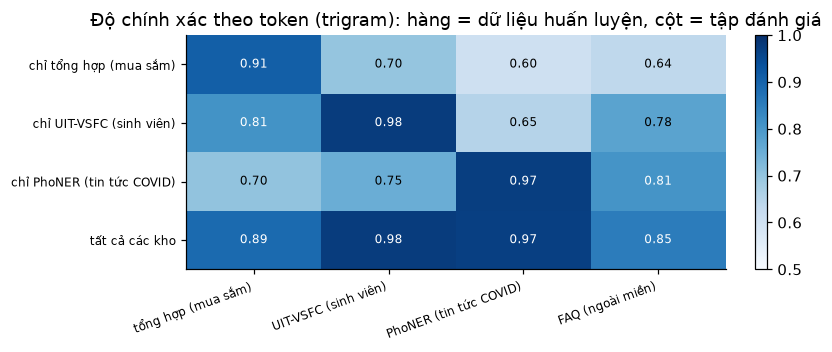

Tỉ lệ câu đúng hoàn toàn (trigram, huấn luyện trên tất cả các kho):
{'tổng hợp (mua sắm) | câu': 0.79, 'UIT-VSFC (sinh viên) | câu': 0.79, 'PhoNER (tin tức COVID) | câu': 0.48, 'FAQ (ngoài miền) | câu': 0.1}


In [10]:
tri = bang_mien.xs(3, level="bậc")[cot_tok]
fig, ax = plt.subplots(figsize=(7.5, 3.3))
im = ax.imshow(tri.values, cmap="Blues", vmin=0.5, vmax=1.0, aspect="auto")
ax.set_xticks(range(tri.shape[1])); ax.set_xticklabels(tri.columns, rotation=20, ha="right", fontsize=8)
ax.set_yticks(range(tri.shape[0])); ax.set_yticklabels(tri.index, fontsize=8)
for i in range(tri.shape[0]):
    for j in range(tri.shape[1]):
        ax.text(j, i, f"{tri.values[i, j]:.2f}", ha="center", va="center", color="white" if tri.values[i, j] > 0.8 else "black", fontsize=8)
ax.set_title("Độ chính xác theo token (trigram): hàng = dữ liệu huấn luyện, cột = tập đánh giá")
plt.colorbar(im, ax=ax, fraction=0.03); plt.tight_layout(); plt.show()

cot_cau = [c for c in bang_mien.columns if "| câu" in c]
print("Tỉ lệ câu đúng hoàn toàn (trigram, huấn luyện trên tất cả các kho):")
print(bang_mien.xs(3, level="bậc").loc[to_hop_cuoi, cot_cau].to_dict())

**Đọc kết quả (5).**

- **Chỉ giỏi trong miền của mình.** Đường chéo của bảng (huấn luyện và đánh giá cùng miền) là ≈ 0,91 / 0,98 / 0,97, còn ra ngoài miền thì rơi mạnh: mô hình UIT-VSFC chỉ đạt 0,65 trên tin tức, mô hình PhoNER đạt 0,75 trên UIT-VSFC, mô hình chỉ học kho tổng hợp (1,3 nghìn câu viết từ khuôn mẫu) đạt 0,60–0,70 ở mọi miền khác. Một con số "97%" vô nghĩa nếu không nói rõ *trên dữ liệu nào*.
- **Gộp nhiều kho giúp ngoài miền.** Huấn luyện trên tất cả các kho giữ nguyên mức trong miền (0,98 và 0,97) và là cấu hình tốt nhất trên FAQ (0,85, so với 0,78 của UIT-VSFC, 0,81 của PhoNER và 0,64 của kho tổng hợp). Nhưng 0,85 vẫn kém xa 0,98: chỉ **10% câu FAQ** đúng hoàn toàn, so với 79% câu UIT-VSFC.
- **Bậc mô hình.** Từ bậc 1 lên bậc 2 là bước nhảy lớn (UIT-VSFC 0,87 → 0,98) vì bắt đầu dùng ngữ cảnh. Từ bậc 2 lên bậc 3 gần như không đổi trên dữ liệu thật (0,977 → 0,976 ở UIT-VSFC, 0,969 → 0,971 ở PhoNER): với ≈ 160 nghìn token, bộ đếm ba âm tiết quá thưa. Trigram chỉ thắng rõ ở kho tổng hợp (khi gộp: 0,84 → 0,89) vì ở đó cụm ba âm tiết lặp lại theo khuôn mẫu — đừng lấy dữ liệu tổng hợp làm bằng chứng cho mô hình phức tạp hơn.

## 6. Phân tích lỗi: lỗi do ngữ cảnh hay do thiếu từ điển?

Một token sai có hai nguyên nhân khác hẳn nhau và cách chữa cũng khác:

1. **Thiếu ứng viên:** dạng đúng *không nằm* trong tập ứng viên $C(x_i)$ nên không thể chọn được. Chữa bằng cách mở rộng từ điển (hoặc thêm dữ liệu).
2. **Chọn sai trong ứng viên:** dạng đúng có trong $C(x_i)$ nhưng mô hình ngôn ngữ ưu tiên dạng khác. Chữa bằng mô hình ngữ cảnh tốt hơn hoặc nhiều dữ liệu hơn.

Ta phân loại lỗi trên tập FAQ với mô hình huấn luyện trên tất cả các kho:

In [11]:
tot_kho = [s for k in ten_kho for s in KHO[k][0]]
m_tot = DiacriticRestorer(bac=3).fit(tot_kho, extra_syllables=lex)
thieu_uv = chon_sai = 0
nham = Counter()
tong = 0
for s in faq_cau:
    pred = m_tot.restore_tokens([strip_accents(w) for w in s])
    for w, p in zip(s, pred):
        tong += 1
        if w != p:
            if w in m_tot.candidates(strip_accents(w)): chon_sai += 1
            else: thieu_uv += 1
            nham[(strip_accents(w), w, p)] += 1
sai = thieu_uv + chon_sai
print(f"{tong} token, sai {sai} ({sai / tong:.1%}): thiếu ứng viên {thieu_uv}, có ứng viên nhưng chọn sai {chon_sai}")

# Từ điển bổ sung (âm tiết trong từ vựng PhoBERT) có giúp không?
m_khong_lex = DiacriticRestorer(bac=3).fit(tot_kho)
dem_thieu = lambda m: sum(w not in m.candidates(strip_accents(w)) for s in faq_cau for w in s)
tok_co, _ = danh_gia_goi(m_tot, faq_cau); tok_khong, _ = danh_gia_goi(m_khong_lex, faq_cau)
print(f"Thiếu ứng viên: có từ điển bổ sung {dem_thieu(m_tot)} | không có {dem_thieu(m_khong_lex)}; độ chính xác token: {tok_co:.3f} | {tok_khong:.3f}")
display(pd.DataFrame([{"không dấu": b, "đúng": g, "mô hình chọn": p, "số lần": n} for (b, g, p), n in nham.most_common(12)]).set_index("không dấu"))

947 token, sai 139 (14.7%): thiếu ứng viên 2, có ứng viên nhưng chọn sai 137


Thiếu ứng viên: có từ điển bổ sung 2 | không có 11; độ chính xác token: 0.853 | 0.853


,đúng,mô hình chọn,số lần
không dấu,,,
dong,đồng,động,7
tra,trả,tra,5
giam,giảm,giám,4
giao,giao,giáo,4
don,đơn,đón,4
bao,bảo,báo,4
gia,giá,gia,4
nhan,nhận,nhân,3
khoan,khoản,khoăn,3


**Đọc kết quả (6).** Trong 947 token FAQ, mô hình sai 139 (14,7%) nhưng **chỉ 2 lỗi do thiếu ứng viên**; 137 lỗi còn lại là dạng đúng *có* trong danh sách nhưng mô hình chọn dạng khác. Từ điển bổ sung từ PhoBERT cứu được 9 trong 11 token thiếu ứng viên, song độ chính xác token không đổi ở mức ba chữ số (0,853 cả hai). Vậy nút thắt là **ngữ cảnh và miền**, không phải từ điển. Các nhầm lẫn hàng đầu cho thấy rõ: từ đúng của miền cửa hàng ("*đồng*", "*giảm*", "*đơn*", "*bảo*") bị kéo về dạng khác thường gặp hơn trong dữ liệu đã học (ví dụ *động* xuất hiện 333 lần so với *đồng* 115 lần trong UIT-VSFC). Cách chữa rẻ nhất là thêm **văn bản có dấu cùng miền** (không cần nhãn) — ý của bài tập 3.

## 7. Ứng dụng: cứu truy vấn không dấu trong tìm kiếm (nối Bài 12)

Bài 12 đã đo: truy vấn không dấu làm sụp cả BM25 lẫn e5, và kết luận "cần một bước khôi phục dấu". Giờ đo thật: khôi phục dấu cho 33 truy vấn FAQ (đã bỏ dấu), rồi xếp hạng như Bài 12. Ta so ba cách xử lý, tài liệu luôn giữ nguyên có dấu:

- **không dấu:** dùng thẳng truy vấn không dấu;
- **khôi phục dấu:** `m_tot.restore(truy vấn)`;
- **bỏ dấu cả hai phía:** chuẩn hóa tài liệu cũng thành không dấu (không cần mô hình nào).

In [12]:
from nlpvi.retrieval import BM25, Embedder, search_tokens, rank_from_scores, evaluate_rankings

id2idx = {d["id"]: i for i, d in enumerate(docs)}
doc_texts = [f"{d['title']}. {d['text']}" for d in docs]
gold = [[id2idx[g] for g in q["gold"]] for q in queries]
q_co_dau = [q["q"] for q in queries]
q_khong_dau = [strip_accents(q) for q in q_co_dau]
q_khoi_phuc = [m_tot.restore(q) for q in q_khong_dau]

dung_tok = sum(x == y for a, b in zip(q_co_dau, q_khoi_phuc) for x, y in zip(tach_token(a), tach_token(b)))
tong_tok = sum(len(tach_token(a)) for a in q_co_dau)
cau_dung = sum(tach_token(a) == tach_token(b) for a, b in zip(q_co_dau, q_khoi_phuc))
print(f"Khôi phục 33 truy vấn: đúng {dung_tok / tong_tok:.1%} số token, {cau_dung}/{len(q_co_dau)} truy vấn đúng hoàn toàn")
for a, b in list(zip(q_co_dau, q_khoi_phuc))[:5]:
    print("  gốc     :", a); print("  khôi phục:", b)

Khôi phục 33 truy vấn: đúng 79.7% số token, 5/33 truy vấn đúng hoàn toàn
  gốc     : Mua hàng xong muốn trả lại thì có bao nhiêu ngày?
  khôi phục: Mua hàng xong muốn tra lại thì cô bao nhiêu ngày?
  gốc     : Tôi bấm nhầm sản phẩm, có thể đổi sang món khác không?
  khôi phục: Tối bám nhàm sản phẩm, có thể đổi sang môn khác không?
  gốc     : Hàng sale 60% có được đổi không?
  khôi phục: Hàng sale 60% có được đổi không?
  gốc     : Bao lâu thì nhận lại tiền sau khi trả hàng?
  khôi phục: Báo lâu thì nhân lại tiên sau khi tra hàng?
  gốc     : Đơn thanh toán khi nhận hàng thì hoàn tiền kiểu gì?
  khôi phục: Đơn thanh toán khi nhận hàng thì hoàn tiễn kiểu gì?


In [13]:
e5 = Embedder("intfloat/multilingual-e5-small", query_prefix="query: ", passage_prefix="passage: ", device="cpu")
D_co_dau = e5.encode(doc_texts, "passage")
D_khong_dau = e5.encode([strip_accents(t) for t in doc_texts], "passage")
bm = BM25([search_tokens(t) for t in doc_texts])
bm_nd = BM25([search_tokens(strip_accents(t)) for t in doc_texts])

def tom_tat(rk):
    m, _ = evaluate_rankings(rk, gold)
    return {k: round(v, 3) for k, v in m.items() if k in ("hit@1", "hit@3", "mrr")}

xh_bm = lambda qs, b: [rank_from_scores(b.scores(search_tokens(q))) for q in qs]
xh_e5 = lambda qs, D=D_co_dau: [rank_from_scores(s) for s in e5.encode(qs, "query") @ D.T]
ket = {
    "BM25 | truy vấn có dấu (mốc trên)": tom_tat(xh_bm(q_co_dau, bm)),
    "BM25 | không dấu": tom_tat(xh_bm(q_khong_dau, bm)),
    "BM25 | không dấu → khôi phục dấu": tom_tat(xh_bm(q_khoi_phuc, bm)),
    "BM25 | bỏ dấu cả hai phía": tom_tat(xh_bm(q_khong_dau, bm_nd)),
    "e5 | truy vấn có dấu (mốc trên)": tom_tat(xh_e5(q_co_dau)),
    "e5 | không dấu": tom_tat(xh_e5(q_khong_dau)),
    "e5 | không dấu → khôi phục dấu": tom_tat(xh_e5(q_khoi_phuc)),
    "e5 | bỏ dấu cả hai phía": tom_tat(xh_e5(q_khong_dau, D_khong_dau)),
}
display(pd.DataFrame(ket).T)

,hit@1,hit@3,mrr
BM25 | truy vấn có dấu (mốc trên),0.909,0.909,0.920
BM25 | không dấu,0.152,0.333,0.306
BM25 | không dấu → khôi phục dấu,0.576,0.667,0.653
BM25 | bỏ dấu cả hai phía,0.848,0.909,0.890
e5 | truy vấn có dấu (mốc trên),0.879,0.970,0.923
e5 | không dấu,0.242,0.485,0.409
e5 | không dấu → khôi phục dấu,0.667,0.818,0.764
e5 | bỏ dấu cả hai phía,0.394,0.636,0.541


**Đọc kết quả (7).**

- Khôi phục dấu 33 truy vấn chỉ đúng **79,7%** token và 5/33 truy vấn đúng hoàn toàn — đúng như mục 5 dự báo vì truy vấn FAQ ở ngoài miền của mô hình.
- **Với e5 (dense):** khôi phục dấu nâng Hit@1 từ 0,242 lên **0,667** (Hit@3: 0,485 → 0,818), vẫn thấp hơn mốc truy vấn có dấu 0,879. Bỏ dấu cả hai phía còn tệ hơn (0,394) vì e5 không quen chữ không dấu ở cả hai phía.
- **Với BM25 (khớp chuỗi):** khôi phục dấu nâng 0,152 → 0,576, nhưng **cách rẻ hơn — bỏ dấu cả hai phía — lại tốt hơn hẳn (0,848)**, gần mốc có dấu (0,909): khi chỉ khớp chuỗi, điều cần là hai phía *nhất quán*, không cần dấu đúng, và khỏi phải chịu lỗi khôi phục. (Bài 12 báo 0,788 cho dòng này vì dùng token âm tiết; ở đây dùng cùng cách tách từ ghép như các dòng khác; chênh 2/33 truy vấn.)
- **Bài học:** chọn cách sửa theo *hệ thống phía sau*. Khôi phục dấu đáng dùng khi bước sau cần chữ có dấu (mô hình dense, PhoBERT); khi chỉ cần khớp từ khóa, chuẩn hóa chung hai phía rẻ và bền hơn.

## 8. (Tùy chọn, cần GPU) So với một LLM nhỏ dùng prompt

LLM đã "đọc" lượng văn bản khổng lồ nên về nguyên tắc biết ngữ cảnh rộng hơn nhiều n-gram. Ta thử `Qwen2.5-1.5B-Instruct` (cùng mô hình Bài 13) với một prompt cố định, trên **24 tài liệu FAQ** (đã bỏ dấu), và so với mô hình n-gram trên đúng các văn bản đó. Vì LLM có thể *đổi số từ*, ta đo bằng độ khớp token theo căn chỉnh `difflib` thay vì so từng vị trí.

In [14]:
import torch
CHAY_LLM = torch.cuda.is_available()
if not CHAY_LLM:
    print("Không có GPU: bỏ qua mục 8.")
else:
    import transformers
    transformers.logging.set_verbosity_error()
    from transformers import AutoTokenizer, AutoModelForCausalLM
    MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
    tok = AutoTokenizer.from_pretrained(MODEL)
    llm = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float16).to("cuda").eval()

    def llm_khoi_phuc(text):
        msgs = [{"role": "system", "content": "Bạn là công cụ thêm dấu tiếng Việt."},
                {"role": "user", "content": "Thêm dấu tiếng Việt đầy đủ và đúng cho đoạn văn không dấu sau. Giữ nguyên từng từ và dấu câu, chỉ thêm dấu, không giải thích.\n\n" + text}]
        ids = tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt", return_dict=True).to("cuda")
        with torch.no_grad():
            out = llm.generate(**ids, max_new_tokens=400, do_sample=False)
        return tok.decode(out[0, ids["input_ids"].shape[1]:], skip_special_tokens=True).strip()

    def khop(gold_toks, pred_toks):
        sm = difflib.SequenceMatcher(a=gold_toks, b=pred_toks, autojunk=False)
        return sum(b.size for b in sm.get_matching_blocks())

    tong_tok, dung = 0, {"n-gram": 0, "Qwen2.5-1.5B (prompt)": 0, "Qwen + kiểm tra kênh nhiễu*": 0}
    giu_chu = 0
    vi_du = None
    t0 = time.time()
    for d in docs:
        g = tach_token(d["text"]); x = strip_accents(d["text"])
        p_ng = tach_token(m_tot.restore(x)); p_llm_text = llm_khoi_phuc(x); p_llm = tach_token(p_llm_text)
        # tính chất kênh nhiễu: bỏ dấu kết quả phải trả đúng đầu vào; nếu LLM đổi chữ thì lùi về n-gram
        giu = tach_token(strip_accents(p_llm_text)) == tach_token(x)
        giu_chu += giu
        tong_tok += len(g)
        dung["n-gram"] += khop(g, p_ng); dung["Qwen2.5-1.5B (prompt)"] += khop(g, p_llm)
        dung["Qwen + kiểm tra kênh nhiễu*"] += khop(g, p_llm if giu else p_ng)
        if vi_du is None and not giu:
            vi_du = (d["text"], p_llm_text)
    print(f"{len(docs)} tài liệu, {time.time() - t0:.0f}s | LLM giữ nguyên chữ (chỉ thêm dấu) ở {giu_chu}/{len(docs)} tài liệu")
    display(pd.DataFrame({k: {"token khớp": round(v / tong_tok, 3)} for k, v in dung.items()}).T)
    print("* nếu bỏ dấu đầu ra của LLM không trả lại đúng đầu vào thì dùng kết quả n-gram thay thế")
    if vi_du:
        print("Gốc :", vi_du[0]); print("LLM :", vi_du[1])
    del llm; torch.cuda.empty_cache()

24 tài liệu, 89s | LLM giữ nguyên chữ (chỉ thêm dấu) ở 1/24 tài liệu


,token khớp
n-gram,0.855
Qwen2.5-1.5B (prompt),0.721
Qwen + kiểm tra kênh nhiễu*,0.827


* nếu bỏ dấu đầu ra của LLM không trả lại đúng đầu vào thì dùng kết quả n-gram thay thế
Gốc : Khách hàng được đổi hoặc trả sản phẩm trong vòng 7 ngày kể từ ngày nhận hàng nếu sản phẩm còn nguyên tem mác và hóa đơn. Sản phẩm giảm giá trên 50% không áp dụng đổi trả.
LLM : Khách hàng được đổi hoặc trả sản phẩm trong vòng 7 ngày kể từ khi nhận hàng nếu sản phẩm có nguồn gốc mẫu mã đẹp và hợp đồng đã ký. Sản phẩm giảm giá trên 50% không áp dụng đổi trả.


**Đọc kết quả (8).** Qwen2.5-1.5B với một prompt cố định chỉ khớp **72,1%** token, thấp hơn mô hình n-gram nhỏ **85,5%** trên cùng 24 tài liệu. Lỗi của LLM khác loại: nó không chỉ chọn sai dấu mà còn **viết lại** — bỏ dấu đầu ra chỉ trả lại đúng đầu vào ở **1/24** tài liệu, nghĩa là ở 23 tài liệu còn lại nó đã đổi, thêm hoặc bớt chữ (ví dụ "còn nguyên tem mác và hóa đơn" thành "có nguồn gốc mẫu mã đẹp và hợp đồng đã ký"). Với tác vụ phải *giữ nguyên chữ*, đó là kiểu lỗi nguy hiểm. Tính chất kênh nhiễu cho ta một phép **kiểm tra tự động** (bỏ dấu kết quả phải bằng đầu vào), nhưng phương án "lùi về n-gram khi LLM đổi chữ" chỉ đạt 0,827 vì kiểm tra này gần như luôn bác bỏ LLM. Kết luận cho ví dụ này: mô hình nhỏ, chuyên biệt, kiểm chứng được thắng một LLM nhỏ dùng prompt. (Một prompt, một mô hình, 24 tài liệu: đừng khái quát cho LLM lớn hơn.)

## 9. Tổng kết

- Khôi phục dấu là chọn **chuỗi có xác suất ngôn ngữ lớn nhất** trong lưới các dạng có dấu khả dĩ: kênh nhiễu tất định + n-gram + Viterbi, cài từ đầu chỉ vài chục dòng.
- Phép bỏ dấu rất mơ hồ (86% token có nhiều hơn một dạng). Baseline "dạng phổ biến nhất" đã đạt 87% token nhưng chỉ 29% câu; ngữ cảnh đưa lên 97,8% token và 79,8% câu — **trong miền**.
- **Ngoài miền thì tụt mạnh** (0,65–0,81 giữa các kho, 0,85 trên FAQ ngay cả khi gộp kho; chỉ 10% câu FAQ đúng hoàn toàn). Luôn nói rõ con số đo *trên dữ liệu nào*.
- Trên dữ liệu thật trigram ≈ bigram; đừng lấy dữ liệu tổng hợp (khuôn mẫu) làm bằng chứng cho mô hình phức tạp hơn.
- Phân tích lỗi cho thấy 137/139 lỗi là do **ngữ cảnh/miền**, không phải thiếu từ điển: chữa bằng văn bản cùng miền hơn là bằng từ điển.
- Ứng dụng tìm kiếm: khôi phục dấu nâng e5 từ 0,242 lên 0,667 Hit@1, nhưng với BM25 thì *bỏ dấu cả hai phía* (0,848) thắng khôi phục dấu (0,576). Chọn theo hệ thống phía sau.
- LLM nhỏ dùng prompt đạt 0,721, thấp hơn n-gram (0,855) và đổi chữ ở 23/24 tài liệu; tính chất kênh nhiễu cho phép kiểm tra tự động đầu ra.

## Bài tập

1. **(Dễ)** Thử các bộ trọng số nội suy $(\lambda_1,\lambda_2,\lambda_3)$ khác nhau, ví dụ $(0{,}3;\,0{,}4;\,0{,}3)$ và $(0{,}02;\,0{,}28;\,0{,}7)$. Độ chính xác trên UIT-VSFC valid thay đổi bao nhiêu? Vì sao *không nên* chọn $\lambda$ bằng tập đánh giá cuối?
2. **(Dễ)** Từ điển bổ sung từ PhoBERT hầu như không đổi độ chính xác trên FAQ (mục 6). Tìm một tập văn bản mà nó **có** ích (gợi ý: văn bản chuyên ngành hoặc nhiều tên riêng) và đo chênh lệch. Làm thế nào ước lượng *trước khi huấn luyện* rằng từ điển sẽ có ích?
3. **(Vừa)** Thêm kho thứ tư: văn bản bạn tự thu thập (ví dụ vài chục câu từ bài báo hoặc chat) và đo lại ma trận mục 5. Mô hình đã "học miền" của bạn tới mức nào?
4. **(Vừa)** Cài **beam search** (giữ $B$ trạng thái tốt nhất mỗi cột) thay cho Viterbi đầy đủ. Với $B=5,20$ độ chính xác và thời gian khác Viterbi thế nào?
5. **(Khó)** Huấn luyện một bộ gán nhãn **BiLSTM** (Bài 7) nhận chuỗi âm tiết không dấu và dự đoán chỉ số dạng có dấu trong danh sách ứng viên. So với n-gram trên cùng dữ liệu, trong miền và ngoài miền.

<details>
<summary><b>Gợi ý đáp án</b></summary>

1. Trong thử nghiệm của chúng tôi, ba bộ $\lambda$ khác nhau cho chênh lệch dưới 0,001 độ chính xác token trên UIT-VSFC valid: với ≈ 160 nghìn token kết quả không nhạy với $\lambda$. Không chọn $\lambda$ trên tập đánh giá cuối vì điểm sẽ **lạc quan**; hãy dùng tập valid riêng hoặc nội suy xóa-một (deleted interpolation).
2. Từ điển chỉ có ích khi có nhiều âm tiết *chưa gặp* trong dữ liệu train. Ước lượng trước bằng tỉ lệ dạng không dấu của tập đích mà `candidates()` không có (như đã đếm ở mục 6: 11/947 token FAQ, tức 1,2%, nếu không có từ điển).
3. Thêm văn bản không nhãn cùng miền thường là cách rẻ nhất. Ở mục 5: chỉ UIT-VSFC cho 0,78 trên FAQ, chỉ PhoNER 0,81, tất cả các kho 0,85. Nhưng văn bản *khác miền* có thể không giúp miền của bạn; luôn đo trên một tập giữ riêng.
4. Beam search: ở mỗi cột chỉ giữ $B$ trạng thái điểm cao nhất; khi $B$ bằng số trạng thái đầy đủ thì trùng Viterbi. Hãy vẽ độ chính xác và thời gian theo $B$.
5. Gán nhãn chuỗi bằng BiLSTM cần nhiều dữ liệu hơn n-gram để thắng; hãy so theo **đường cong học** (độ chính xác theo lượng dữ liệu train) và đo cả ngoài miền, chứ đừng chỉ so một điểm.

**Đáp án bằng mã** (bài tập 1, 2, 4): [dap_an/17_dap_an_bai_17.ipynb](dap_an/17_dap_an_bai_17.ipynb).
</details>

**Tiếp theo →** [Bài 18 · Phân cụm và mô hình chủ đề](18_phan_cum_va_chu_de.ipynb) hoặc quay lại [docs/GIAO_TRINH.md](../docs/GIAO_TRINH.md).

**Đọc thêm:** Jurafsky & Martin, *Speech and Language Processing*, chương về mô hình ngôn ngữ và kênh nhiễu · Kernighan, Church & Gale (1990), *A spelling correction program based on a noisy channel model*